# Decision Tree — resultados organizados

Mantemos os mesmos modelos, hiperparâmetros, treino, teste e validações do projeto. **SIM=1** é a classe positiva; **NAO=0** é a negativa. Percentuais aparecem com duas casas e MCC com quatro. As tabelas são calculadas automaticamente.

In [1]:
import pandas as pd # permite organizar os resultados em tabelas
from sklearn.tree import DecisionTreeClassifier # importa a árvore de decisão já usada
from sklearn.metrics import ( # importa as métricas calculadas automaticamente
    confusion_matrix, # conta os acertos e erros de cada classe
    ConfusionMatrixDisplay, # desenha a matriz de confusão
    make_scorer, # adapta o mcc para a validação cruzada
    matthews_corrcoef, # avalia os acertos e erros das duas classes
    accuracy_score, # calcula a proporção total de acertos
    precision_score, # calcula os acertos entre os alertas de chuva
    recall_score, # mede a detecção de chuva ou de ausência de chuva
    f1_score, # equilibra precisão e sensibilidade
)
from sklearn.model_selection import cross_val_score # avalia as partes do treino
import matplotlib.pyplot as plt # permite desenhar as matrizes

def avaliar_modelo(real, previsto): # calcula as métricas sem treinar outro modelo
    return { # guarda as métricas sem arredondar os cálculos
        # acurácia: mostra a proporção total de previsões corretas
        'Acurácia': accuracy_score(real, previsto), # mede o total de previsões corretas
        # precisão: das vezes em que o modelo disse que choveu, quantas ele acertou
        'Precisão SIM': precision_score(real, previsto, pos_label=1, zero_division=0), # avalia os alertas de chuva
        # sensibilidade: das vezes em que realmente choveu, quantas o modelo identificou
        'Sensibilidade SIM': recall_score(real, previsto, pos_label=1, zero_division=0), # mede as chuvas encontradas
        # especificidade: das vezes em que não choveu, quantas o modelo identificou corretamente
        'Especificidade': recall_score(real, previsto, pos_label=0, zero_division=0), # mede as horas sem chuva identificadas
        # f1-score: mede o equilíbrio entre precisão e sensibilidade
        'F1 SIM': f1_score(real, previsto, pos_label=1, zero_division=0), # equilibra precisão e detecção de chuva
        # mcc: considera acertos e erros das duas classes em uma medida de menos um a um
        'MCC': matthews_corrcoef(real, previsto), # considera as quatro partes da matriz
    }

def formatar_metricas(tabela): # muda somente a exibição das métricas
    exibicao = tabela.copy() # preserva os resultados numéricos originais
    for coluna in tabela.columns: # escolhe o formato de cada métrica
        formato = '{:.4f}' if coluna == 'MCC' else '{:.2%}' # separa mcc dos percentuais
        exibicao[coluna] = tabela[coluna].map(formato.format) # aplica o formato sem mudar os cálculos
    return exibicao # devolve uma tabela simples para a apresentação


## 1. Árvore inicial

Divisão aleatória estratificada: 80% treino e 20% teste, com semente 42. O notebook 07 também cria um treino balanceado, mas a árvore existente usa **X_train e y_train sem undersampling**.

In [2]:
# executa o notebook que cria as divisões de treino e teste
print("Registros da divisão — treino e teste, nessa ordem:") # identifica as quantidades exibidas
%run 07_divisao_e_balanceamento.ipynb

# decision tree: aprende perguntas e limites sobre os atributos para chegar a uma classe
# hiperparâmetros: são escolhas feitas antes do treino, como profundidade e número de árvores
modelo = DecisionTreeClassifier( # cria a árvore inicial com os parâmetros escolhidos
    # gini: mede a mistura das classes para ajudar a escolher as divisões da árvore
    criterion='gini', # usa gini para medir a mistura das classes em cada divisão
    # overfitting: acontece quando o modelo aprende detalhes demais do treino e falha em dados novos
    # underfitting: acontece quando o modelo é simples demais para aprender os padrões importantes
    max_depth=5, # limita a profundidade da árvore a cinco níveis de divisões
    min_samples_split=10, # exige pelo menos dez registros para dividir um nó
    # random_state: fixa os sorteios para permitir repetir os resultados
    random_state=42 # fixa a aleatoriedade para permitir repetir o resultado
)

# aprendizado supervisionado: aprende com exemplos que já possuem a resposta correta
# parâmetros: são as regras e os limites que o modelo aprende durante o treino
modelo.fit(X_train, y_train) # treina a árvore com o treino sem balanceamento

# classificação binária: escolhe entre duas classes, aqui chuva ou ausência de chuva
y_pred = modelo.predict(X_test) # classifica os registros separados para teste

metricas_iniciais = avaliar_modelo(y_test, y_pred) # guarda as métricas de teste da árvore inicial
print("Árvore inicial treinada; métricas guardadas para a comparação final") # identifica esta etapa


Registros da divisão — treino e teste, nessa ordem:


7004 1752
Árvore inicial treinada; métricas guardadas para a comparação final


## 2. Matriz de confusão — árvore inicial

Linhas são classes reais e colunas são previsões. A ordem **[NAO=0, SIM=1]** produz `[[vn, fp], [fn, vp]]`. Logo, 1.401 é verdadeiro negativo e 147 é verdadeiro positivo nesta execução; não devemos inverter a classe positiva.

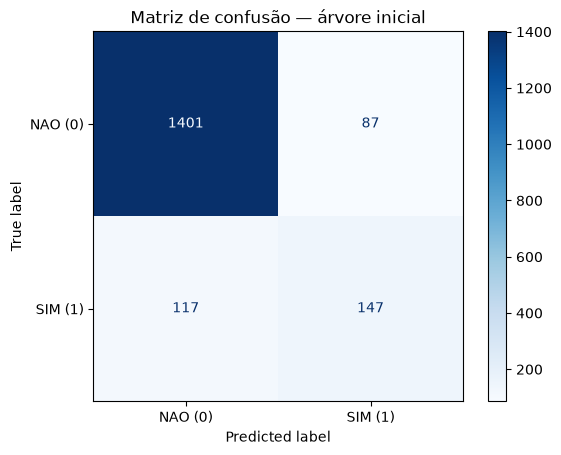

In [3]:
# matriz de confusão: compara classes reais nas linhas com classes previstas nas colunas
cm = confusion_matrix(y_test, y_pred) # conta acertos e erros, com classes reais nas linhas e previstas nas colunas

# display_labels usa a ordem das classes aprendidas pelo modelo
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['NAO (0)', 'SIM (1)']) # prepara a matriz para ser desenhada
disp.plot(cmap=plt.cm.Blues) # desenha a matriz usando tons de azul

plt.title("Matriz de confusão — árvore inicial") # define o título do gráfico
plt.show() # mostra o gráfico da matriz de confusão


## 3. Validação cruzada — MCC da árvore inicial

São cinco folds estratificados dentro do treino, como no código original. A média abaixo é **MCC de validação**, e não MCC do teste.

In [4]:
mcc_scorer = make_scorer(matthews_corrcoef) # prepara o mcc para ser usado na validação cruzada

# cv=5 avalia em cinco partes com proporções semelhantes das classes
# scoring usa o mcc, que considera as duas classes na avaliação
# cross-validation: avalia o modelo em diferentes partes dos dados de treinamento
scores = cross_val_score(modelo, X_train, y_train, cv=5, scoring=mcc_scorer) # mede o modelo em partes do treino que ele não usou para aprender
print(f"MCC médio — validação cruzada (5 folds), árvore inicial: {scores.mean():.4f}") # mostra a média do mcc obtido nas cinco avaliações


MCC médio — validação cruzada (5 folds), árvore inicial: 0.5275


## 4. Validação cruzada — F1 de uma árvore padrão

Esta etapa original cria uma árvore com os parâmetros padrão e semente 42. **Não é a árvore inicial limitada a profundidade 5.** O F1 é da classe SIM e não utiliza o teste.

In [5]:
# aqui a árvore usa os demais parâmetros padrão da biblioteca
modelo = DecisionTreeClassifier(random_state=42) # cria outra árvore com aleatoriedade fixa para avaliar por f1
# cv=5 faz cinco avaliações em partes diferentes do treino
# scoring=f1 equilibra a precisão e a detecção de chuva
# cross-validation: avalia o modelo em diferentes partes dos dados de treinamento
scores = cross_val_score(modelo, X_train, y_train, cv=5, scoring="f1") # calcula um f1 para cada parte usada na validação

print(f"F1 médio — validação cruzada (5 folds), árvore padrão: {scores.mean():.2%}")
print(f"Desvio do F1 — validação cruzada: {scores.std():.2%}") # mostra a variação entre os folds # mostra o f1 médio e quanto ele varia entre as avaliações


F1 médio — validação cruzada (5 folds), árvore padrão: 56.89%
Desvio do F1 — validação cruzada: 2.78%


## 5. Grid Search

Mantemos as 36 combinações e os cinco folds do projeto. A busca usa somente o treino e escolhe pelo F1 de SIM. Os resultados são reunidos na tabela após o Random Search.

In [6]:
from sklearn.model_selection import GridSearchCV # importa a busca que testa todas as combinações da lista
from sklearn.tree import DecisionTreeClassifier # importa o classificador usado nas combinações da busca
# grid search: testa todas as combinações de hiperparâmetros definidas
param_grid = { # define os valores de parâmetros que serão combinados
 "max_depth": [2, 3, 4, 5, 6, None], # testa estas profundidades; none permite crescer sem limite de profundidade
 # gini: mede a mistura das classes para ajudar a escolher as divisões da árvore
 # entropy: mede a incerteza das classes para ajudar a escolher as divisões da árvore
 "criterion": ["gini", "entropy"], # testa duas formas de medir a mistura das classes
 "min_samples_leaf": [1, 5, 10], # testa o mínimo de registros permitido em cada folha
}
# random_state=42 fixa a aleatoriedade da árvore
grid = GridSearchCV(DecisionTreeClassifier(random_state=42), # cria a busca completa usando uma árvore de decisão
 # param_grid fornece as trinta e seis combinações
 # scoring=f1 escolhe a combinação pelo equilíbrio entre precisão e detecção
 # cv=5 avalia cada combinação em cinco partes do treino
 # n_jobs=-1 usa todos os processadores disponíveis
 param_grid, scoring="f1", cv=5, n_jobs=-1) # define como as combinações serão avaliadas
grid.fit(X_train, y_train) # testa as combinações e ajusta a melhor árvore com todo o treino

resultado_grid = { # registra a configuração e separa validação de teste
    'Busca': 'Grid Search', # identifica a busca completa
    'Critério': grid.best_params_['criterion'], # mostra o critério encontrado
    'Profundidade': grid.best_params_['max_depth'], # mostra o limite encontrado
    'Mínimo por folha': grid.best_params_['min_samples_leaf'], # mostra o tamanho mínimo encontrado
    'F1 médio — CV (5 folds)': f'{grid.best_score_:.2%}', # mostra a média de validação
    'F1 — teste': f'{grid.score(X_test, y_test):.2%}', # mostra o f1 no teste, não a acurácia
}
print('Grid Search concluído: 36 combinações e 5 folds') # identifica o fim desta busca


Grid Search concluído: 36 combinações e 5 folds


## 6. Random Search e comparação das buscas

Mantemos os mesmos intervalos, 15 sorteios e cinco folds. A tabela separa a métrica que escolhe os parâmetros (**CV**) da avaliação no teste. Grid teve maior F1 médio de validação; Random teve maior F1 de teste. Portanto, não existe superioridade geral do Random Search.

In [7]:
from sklearn.model_selection import RandomizedSearchCV # importa a busca que sorteia combinações de parâmetros
from scipy.stats import randint # importa a distribuição usada para sortear números inteiros
# random search: sorteia algumas combinações de hiperparâmetros para testar
param_dist = { # define os valores e intervalos que poderão ser sorteados
 "max_depth": randint(2, 15), # sorteia uma profundidade de dois a catorze, sem incluir quinze
 "criterion": ["gini", "entropy"], # sorteia uma das duas formas de medir a mistura das classes
 "min_samples_leaf": randint(1, 20), # sorteia o mínimo por folha de um a dezenove, sem incluir vinte
}
# random_state=42 fixa a aleatoriedade da árvore usada na busca
busca = RandomizedSearchCV(DecisionTreeClassifier(random_state=42), # cria a busca aleatória usando uma árvore de decisão
 # param_dist fornece os valores e intervalos do sorteio
 # n_iter=15 testa quinze combinações sorteadas
 # scoring=f1 compara as combinações pelo f1 da classe chuva
 param_dist, n_iter=15, scoring="f1", # define quantas combinações serão testadas e a métrica usada
 # cv=5 avalia cada combinação em cinco partes do treino
 # n_jobs=-1 usa todos os processadores disponíveis
 # random_state=42 permite repetir o sorteio das combinações
 cv=5, n_jobs=-1, random_state=42) # configura a validação e a aleatoriedade da busca
busca.fit(X_train, y_train) # avalia os sorteios e ajusta a melhor árvore com todo o treino
resultado_random = { # registra os resultados da busca aleatória
    'Busca': 'Random Search', # identifica a busca por sorteio
    'Critério': busca.best_params_['criterion'], # mostra o critério encontrado
    'Profundidade': busca.best_params_['max_depth'], # mostra o limite encontrado
    'Mínimo por folha': busca.best_params_['min_samples_leaf'], # mostra o mínimo encontrado
    'F1 médio — CV (5 folds)': f'{busca.best_score_:.2%}', # mostra a média de validação
    'F1 — teste': f'{busca.score(X_test, y_test):.2%}', # mostra o f1 obtido no teste
}
display(pd.DataFrame([resultado_grid, resultado_random])) # compara as buscas sem misturar as avaliações


,Busca,Critério,Profundidade,Mínimo por folha,F1 médio — CV (5 folds),F1 — teste
0,Grid Search,entropy,6,10,63.03%,58.30%
1,Random Search,entropy,9,3,61.41%,62.65%


## 7. Árvore ajustada já existente

Preservamos os parâmetros escritos no projeto: entropy, profundidade 9 e mínimo de 3 registros por folha. Eles coincidem com a combinação do Random Search. **Não trocamos o modelo para melhorar a métrica desta apresentação.** A escolha histórica pode ter sido influenciada pelo teste; a correção dessa metodologia fica para outra etapa.

In [8]:
# recria as mesmas divisões de treino e teste pelo notebook anterior
print("Registros da divisão — treino e teste, nessa ordem:") # identifica as quantidades exibidas
%run 07_divisao_e_balanceamento.ipynb

modelo_hiperparametrizado = DecisionTreeClassifier( # cria a árvore com os parâmetros escolhidos após a busca
    # entropy: mede a incerteza das classes para ajudar a escolher as divisões da árvore
    criterion='entropy', # usa entropia para medir a mistura das classes nas divisões
    max_depth=9, # limita a profundidade da árvore a nove níveis de divisões
    min_samples_leaf=3, # mantém pelo menos três registros em cada folha
    random_state=42 # fixa a aleatoriedade para permitir repetir o resultado
)

modelo_hiperparametrizado.fit(X_train, y_train) # treina a árvore ajustada com o treino sem balanceamento

y_pred = modelo_hiperparametrizado.predict(X_test) # classifica os registros de teste com a árvore ajustada

metricas_ajustadas = avaliar_modelo(y_test, y_pred) # guarda as métricas do mesmo teste após o ajuste
print("Árvore ajustada treinada com os parâmetros já existentes") # identifica esta etapa


Registros da divisão — treino e teste, nessa ordem:
7004 1752
Árvore ajustada treinada com os parâmetros já existentes


## 8. Matriz de confusão — árvore ajustada

Mantemos a mesma ordem: NAO primeiro e SIM depois. Os acertos de chuva ficam na célula inferior direita; os casos de chuva perdidos ficam na inferior esquerda.

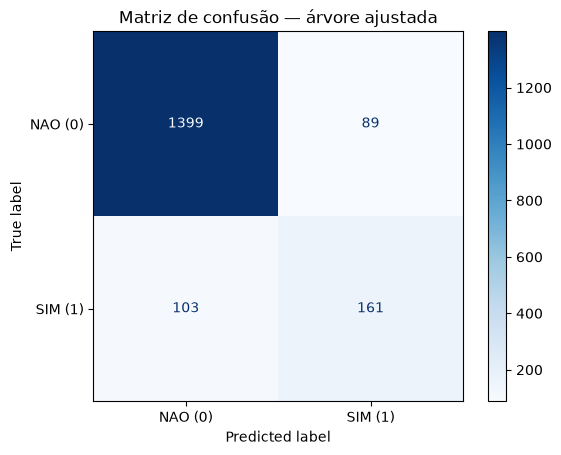

In [9]:
# matriz de confusão: compara classes reais nas linhas com classes previstas nas colunas
cm = confusion_matrix(y_test, y_pred) # conta acertos e erros, com classes reais nas linhas e previstas nas colunas

# display_labels usa a ordem das classes aprendidas pelo modelo
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['NAO (0)', 'SIM (1)']) # prepara a matriz para ser desenhada
disp.plot(cmap=plt.cm.Blues) # desenha a matriz usando tons de azul

plt.title("Matriz de confusão — árvore ajustada") # define o título do gráfico
plt.show() # mostra o gráfico da matriz de confusão


## 9. Validação cruzada — MCC da árvore ajustada

Esta é a média dos cinco folds do treino. O MCC do teste aparece separadamente na comparação final.

In [10]:
mcc_scorer = make_scorer(matthews_corrcoef) # prepara o mcc para ser usado na validação cruzada

# cv=5 avalia em cinco partes com proporções semelhantes das classes
# scoring usa o mcc, que considera as duas classes na avaliação
# cross-validation: avalia o modelo em diferentes partes dos dados de treinamento
scores = cross_val_score(modelo_hiperparametrizado, X_train, y_train, cv=5, scoring=mcc_scorer) # mede o modelo em partes do treino que ele não usou para aprender
print(f"MCC médio — validação cruzada (5 folds), árvore ajustada: {scores.mean():.4f}") # mostra a média do mcc obtido nas cinco avaliações


MCC médio — validação cruzada (5 folds), árvore ajustada: 0.5467


## 10. Comparação no mesmo conjunto de teste

Todas as métricas abaixo são calculadas pelo scikit-learn. Precisão, sensibilidade e F1 usam SIM=1; especificidade é o recall de NAO=0. Percentuais têm duas casas decimais e MCC tem quatro. O arredondamento afeta somente a apresentação.

**Pendências preservadas:** o pré-processamento da árvore foi ajustado antes da divisão; o undersampling não entra neste treino; os folds são estratificados, não temporais. Não comparamos diretamente estes resultados com a Random Forest, que usa outro teste.

In [11]:
comparacao_teste = pd.DataFrame({ # reúne as métricas calculadas nos dois momentos
    'Árvore inicial': metricas_iniciais, # usa as previsões iniciais já calculadas
    'Árvore ajustada': metricas_ajustadas, # usa as previsões da árvore já ajustada
}).T # coloca os modelos nas linhas da tabela
print('Métricas no teste reservado — classe positiva: SIM=1') # identifica o conjunto avaliado
display(formatar_metricas(comparacao_teste)) # mostra os percentuais e o mcc formatados


Métricas no teste reservado — classe positiva: SIM=1


,Acurácia,Precisão SIM,Sensibilidade SIM,Especificidade,F1 SIM,MCC
Árvore inicial,88.36%,62.82%,55.68%,94.15%,59.04%,0.5241
Árvore ajustada,89.04%,64.40%,60.98%,94.02%,62.65%,0.5626
